In [2]:
import os
import struct
import gzip
import hashlib
import urllib.request
import numpy as np

In [3]:
# Download MNIST

MNIST_URL = "https://storage.googleapis.com/cvdf-datasets/mnist/"
MNIST_TEST_FILES = {
    "test_images": ("t10k-images-idx3-ubyte.gz", "8d422c7b0a1c1c79245a5bcf07fe86e33eeafee792b84584aec276f5a2dbc4e6"),
    "test_labels": ("t10k-labels-idx1-ubyte.gz", "f7ae60f92e00ec6debd23a6088c31dbd2371eca3ffa0defaefb259924204aec6"),
}
DATA_DIR = "mnist_data"

def _download_file(filename: str, expected_sha256: str) -> str:
    os.makedirs(DATA_DIR, exist_ok=True)
    filepath = os.path.join(DATA_DIR, filename)
    if os.path.exists(filepath):
        sha = hashlib.sha256(open(filepath, "rb").read()).hexdigest()
        if sha == expected_sha256:
            return filepath
        print(f"Hash mismatch for {filename}, re-downloading …")

    url = MNIST_URL + filename
    print(f"Downloading {url} …")
    urllib.request.urlretrieve(url, filepath)

    sha = hashlib.sha256(open(filepath, "rb").read()).hexdigest()
    if sha != expected_sha256:
        raise RuntimeError(
            f"SHA-256 mismatch for {filename}: expected {expected_sha256}, got {sha}"
        )
    return filepath

def _parse_images(filepath: str) -> np.ndarray:
    """Parse IDX image file -> (N, 1, 28, 28) float32 in [0, 1]."""
    with gzip.open(filepath, "rb") as f:
        _, num, rows, cols = struct.unpack(">IIII", f.read(16))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.reshape(num, 1, rows, cols).astype(np.float32) / 255.0

def _parse_labels(filepath: str) -> np.ndarray:
    """Parse IDX label file -> (N,) int32."""
    with gzip.open(filepath, "rb") as f:
        _, num = struct.unpack(">II", f.read(8))
        data = np.frombuffer(f.read(), dtype=np.uint8)
    return data.astype(np.int32)

def load_mnist_test():
    """Return (test_images, test_labels)."""
    paths = {k: _download_file(*v) for k, v in MNIST_TEST_FILES.items()}
    return _parse_images(paths["test_images"]), _parse_labels(paths["test_labels"])

test_images, test_labels = load_mnist_test()
print(f"\nTest set: {test_images.shape[0]} images, shape={test_images.shape}")


Test set: 10000 images, shape=(10000, 1, 28, 28)


In [4]:
# Load parameters

PARAM_NAMES = [
    "conv1_weight",
    "conv1_bias",
    "conv2_weight",
    "conv2_bias",
    "fc1_weight",
    "fc1_bias",
    "fc2_weight",
    "fc2_bias",
]
PARAMS_DIR = "params"


def load_params(params_dir: str) -> dict:
    """Load all .npy parameter files from params_dir into a dict."""
    params = {}
    print("Parameter\tShape")
    for name in PARAM_NAMES:
        filepath = os.path.join(params_dir, f"{name}.npy")
        if not os.path.exists(filepath):
            raise FileNotFoundError(
                f"Parameter file not found: {filepath}\n"
                "Make sure the params/ folder is in the working directory."
            )
        params[name] = np.load(filepath).astype(np.float32)
        print(f"{name}\t{params[name].shape}")
    return params

params = load_params(PARAMS_DIR)

Parameter	Shape
conv1_weight	(32, 1, 3, 3)
conv1_bias	(32,)
conv2_weight	(64, 32, 3, 3)
conv2_bias	(64,)
fc1_weight	(128, 1024)
fc1_bias	(128,)
fc2_weight	(10, 128)
fc2_bias	(10,)


In [5]:
def conv2d(x: np.ndarray, w: np.ndarray, b: np.ndarray,
            stride: int, padding: int) -> np.ndarray:
    """
    Bidimensional convolution from C_in input channels to C_out output channels.
    The convolution has kernel size (kH x kW) and arbitrary stride and padding.

    Shapes:
      - W: (C_out, C_in, kH, kW) 
      - b: (C_out,)
    """
    # estrazione delle dimensioni dei tensori tramite spacchettamento di tuple:
    # x: batch_size, canali_input (profondità dell'immagine), altezza, larghezza
    # w: canali_output (numero dei filtri), canali_input (profondità del filtro), altezza_kernel, larghezza_kernel
    N, C_in, H_in, W_in = x.shape
    C_out, C_in_w, kH, kW = w.shape # w = banco dei filtri
    
    # la profondità dell'immagine deve combaciare con la profondità dei filtri (i filtri sono 3D, mentre i kernel 2D)
    assert C_in == C_in_w, "Errore, i canali di input non corrispondono."
    
    # calcolo delle dimensioni della mappa di output (feature map)
    H_out = int((H_in - kH + 2 * padding) / stride) + 1
    W_out = int((W_in - kW + 2 * padding) / stride) +1
    
    # inizializzazione dell'output a 0 (out è l'insieme di tutte le feature maps per tutte le immagini del batch)
    out = np.zeros((N, C_out, H_out, W_out))
    
    # aggiunta del padding su H e W per preservare le info spaziali anche ai bordi delle immagini
    # np.pad vuole una direttiva (prima, dopo) per ogni dimensione del tensore 4D, per questo si inserisce (0,0) sulle 
    # dimensioni N e C così da non alterare la quantità di immagini e i canali originali
    # la modalità constant riempe i bordi con una costante (in modo fisso) il cui valore è 0
    x_padded = np.pad(x, ((0, 0), (0, 0), (padding, padding), (padding, padding)), mode = "constant", constant_values = 0) 
    
    # operazione di convoluzione 
    for i in range(H_out): # i cicli annidati implementano il meccanismo di sliding window
      for j in range (W_out):
        
        # calcolo dei confini del receptive field = porzione di immagine di input su cui il filtro si focalizza 
        h_start = i * stride
        h_end = h_start + kH
        w_start = j * stride
        w_end = w_start + kW
        
        receptive_field = x_padded[:, :, h_start:h_end, w_start:w_end]
        
        # iterazione sui filtri
        for c in range(C_out):
          filter_c = w[c, :, :, :]
          
          # moltiplicazione element-wise seguita da np.sum che comprime la profondità e le dimensioni spaziali in un singolo numero ( = pixel della feature map)
          out[:, c, i, j] = np.sum(receptive_field *filter_c, axis=(1, 2, 3)) + b[c]
    
    return out 

In [6]:
def max_pool(x: np.ndarray, pool_size: int = 2, stride: int = 2,) -> np.ndarray:
    """
    Max-pooling with arbitrary pool size and stride.
    """
    # spacchettamento del tensore 4D in cui la profondità è indicata con C
    # perché nel max_pool la profondità di input e di output coincidono
    N, C, H_in, W_in = x.shape
    
    # calcolo delle dimensioni delle feature maps senza padding 
    H_out = int((H_in - pool_size) / stride) + 1
    W_out = int((W_in - pool_size) / stride) +1
    
    out = np.zeros((N, C, H_out, W_out))
    
    for i in range(H_out):
        for j in range(W_out):
            
            h_start = i*stride
            h_end = h_start + pool_size
            w_start = j*stride
            w_end = w_start + pool_size
            
            receptive_field = x[:, :, h_start:h_end, w_start:w_end]
            
            # np.max trova il valore massimo tra h e w nel receptive_field
            out[:, :, i, j] = np.max(receptive_field, axis=(2, 3))
    
    return out

In [7]:
def avg_pool(x: np.ndarray, pool_size: int = 2, stride: int = 2) -> np.ndarray:
    """
    Average-pooling with arbitrary pool size and stride.
    """
    N, C, H_in, W_in = x.shape
    
    H_out = int((H_in - pool_size) / stride) +1
    W_out = int((W_in - pool_size) / stride) +1
    
    out = np.zeros((N, C, H_out, W_out))
    
    for i in range(H_out):
        for j in range(W_out):
            
            h_start = i*stride
            h_end = h_start + pool_size
            w_start = j*stride
            w_end = w_start + pool_size
            
            receptive_field = x[:, :, h_start:h_end, w_start:w_end]
            
            out[:, :, i, j] = np.mean(receptive_field, axis=(2,3))
    
    return out

In [8]:
def relu(x: np.ndarray) -> np.ndarray:
    """
    Rectified Linear Unit activation.
    """
    # np.maximum sostituisce, tramite operazione element-wise, tutti i valori negativi
    # del tensore con 0, preservando i valori positivi
    out = np.maximum(0, x)
    return out 

In [9]:
def cnn_forward(params: dict, x: np.ndarray) -> np.ndarray:
    """
    Forward pass of the CNN using pure NumPy.
    The architecture is:
        Conv1 (1->32, 3x3 kernel, stride=2, padding=1) -> ReLU -> AvgPool(2x2, stride=2)
        Conv2 (32->64, 3x3 kernel, stride=1, padding=2) -> ReLU -> MaxPool(2x2, stride=2)
        Flatten
        FC1 (1024->128) -> ReLU
        FC2 (128->10)
    """
    # prima convoluzione
    conv1 = conv2d(x, params['conv1_weight'], params['conv1_bias'], stride=2, padding=1)
    relu1 = relu(conv1)
    pool1 = avg_pool(relu1, pool_size=2, stride=2)
    
    # seconda convoluzione 
    conv2= conv2d(pool1, params['conv2_weight'], params['conv2_bias'], stride = 1, padding=2)
    relu2 = relu(conv2)
    pool2 = max_pool(relu2, pool_size = 2, stride = 2)
    
    # estrazione di N dal tensore pool per mantenere le immagini indipendenti
    N = pool2.shape[0]
    flat = pool2.reshape(N, -1) # il tensore viene appiattito mantenendo N righe separate e 
                                # calcolando in automatico (tramite -1) il numero totale di features per riga
    
    fc1 = flat @ params['fc1_weight'].T + params['fc1_bias'] # prodotto scalare tra vettore appiattito e pesi con aggiunta del bias
    relu3 = relu(fc1)
    
    # output layer 
    out = relu3 @ params['fc2_weight'].T + params['fc2_bias']
    
    return out 

In [10]:
indices = np.array([0, 1, 78, 320])
sample_images = test_images[indices]
sample_labels = test_labels[indices]

# Perform forward pass
logits = cnn_forward(params, sample_images)
predictions = np.argmax(logits, axis=-1)

for i in range(4):
    print(f"Index {i} | GT={sample_labels[i]} | cnn(x)={predictions[i]}")

Index 0 | GT=7 | cnn(x)=7
Index 1 | GT=2 | cnn(x)=2
Index 2 | GT=9 | cnn(x)=8
Index 3 | GT=9 | cnn(x)=8


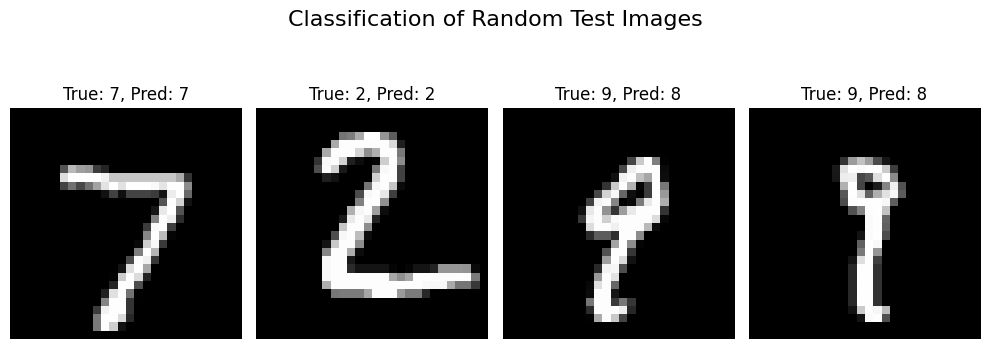

In [11]:
import matplotlib.pyplot as plt

# Display the images and their classifications
plt.figure(figsize=(10, 4))
for i in range(4):
    plt.subplot(1, 4, i + 1)
    plt.imshow(sample_images[i].reshape(28, 28), cmap='gray')
    plt.title(f"True: {sample_labels[i]}, Pred: {predictions[i]}")
    plt.axis('off')
plt.suptitle('Classification of Random Test Images', fontsize=16)
plt.tight_layout(rect=[0, 0.03, 1, 0.95])
plt.show()